In [61]:
from top_down_tree_builder import *
N = 200
data = np.random.randn(N, 2)*300
k=4
tree_idx, global_data, kt, row_lens = scatter_tree_build(data,k)
tree_dictionary = gather_tree_dictionary(tree_idx, global_data, N, k, kt, row_lens)
print(f'Valid_CHECK: {sum(tree_idx[0:N])}')
d1 = check_count(tree_idx[N:])
d2 = check_count(global_data[N:])
treesum = len(tree_dictionary) + sum([len([i for i in v if i > N]) for k,v in tree_dictionary.items()])
print(f'TREE NODES: {treesum}')
print(f'TREE REF ARRAY: {d1}/{len(tree_idx[N:])}  @ {d1/len(tree_idx[N:])} density')
print(f'TREE DATA ARRAY:{d2}/{len(global_data[N:])} @ {d2/len(global_data[N:])} density')
print(f'+{"="*50}')
for i,e in enumerate(global_data):
  if i == N:
    print(f'+{"="*50}')

  print(f'| {i}:\t{tree_idx[i]}\t{global_data[i]}')

[1, 5, 21, 85, 341, 1365]
5460
Valid_CHECK: -200
TREE NODES: 684
TREE REF ARRAY: 344/1365  @ 0.252014652014652 density
TREE DATA ARRAY:144/1365 @ 0.1054945054945055 density
+==================================================
| 0:	-1	[213.92426795 100.50874288]
| 1:	-1	[-119.67286312   79.27933185]
| 2:	-1	[506.56692286 101.16431029]
| 3:	-1	[-127.76048612  106.669247  ]
| 4:	-1	[-373.14958012  174.70804733]
| 5:	-1	[ -30.35289219 -199.93970896]
| 6:	-1	[-58.97099397  47.68187045]
| 7:	-1	[ 313.20142881 -237.28663068]
| 8:	-1	[133.17586227 657.70769929]
| 9:	-1	[338.46033269 320.24223145]
| 10:	-1	[ 3.97962144 72.16091725]
| 11:	-1	[147.36498941 -29.66196943]
| 12:	-1	[-223.96363166 -110.90100801]
| 13:	-1	[112.46613683 -40.75313004]
| 14:	-1	[  70.09733235 -120.41395487]
| 15:	-1	[224.10360712 444.30347566]
| 16:	-1	[ 38.7261986 337.1102247]
| 17:	-1	[-473.32515008 -216.29287319]
| 18:	-1	[581.08609898 277.92084382]
| 19:	-1	[ -43.55265519 -747.8530336 ]
| 20:	-1	[114.33216285 -35.4188

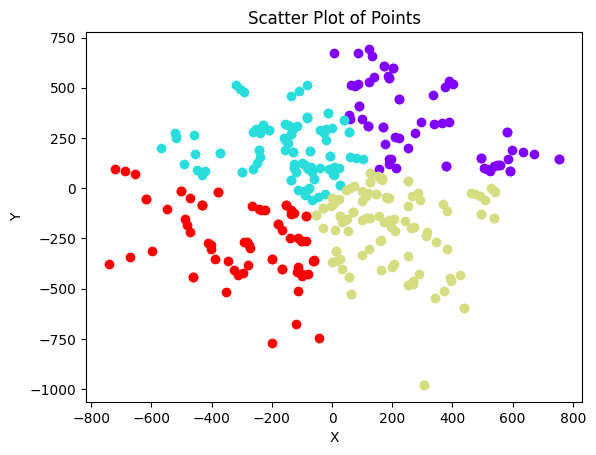

In [62]:
clusters = get_clusters(tree_dictionary, global_data, N, k)
# print(clusters)
draw_clusters(clusters[0:4])

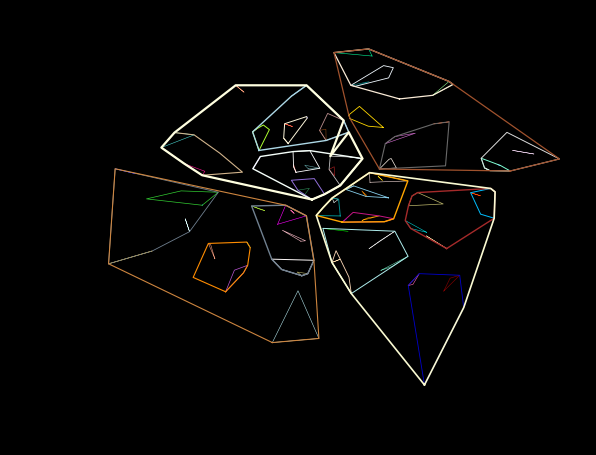

In [75]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
colors = list(set(mcolors.CSS4_COLORS))
# Function to calculate polar angle between points
def polar_angle(p0, p1):
    return np.arctan2(p1[1] - p0[1], p1[0] - p0[0])

def graham_scan_convex_hull(points):
    def cross_product(p, q, r):
        return (q[0] - p[0]) * (r[1] - p[1]) - (r[0] - p[0]) * (q[1] - p[1])

    def polar_angle(p, q):
        return np.arctan2(q[1] - p[1], q[0] - p[0])

    # Find the point with the lowest y-coordinate (and leftmost if tied)
    start_point = min(points, key=lambda p: (p[1], p[0]))

    # Sort the points based on polar angles with respect to the start point
    sorted_points = sorted(
        points, key=lambda p: (polar_angle(start_point, p), -p[1], p[0])
    )

    # Initialize the convex hull with the first three sorted points
    convex_hull = [sorted_points[0], sorted_points[1], sorted_points[2]]

    # Iterate through the sorted points and construct the convex hull
    for point in sorted_points[3:]:
        while (
            len(convex_hull) >= 2
            and cross_product(convex_hull[-2], convex_hull[-1], point) <= 0
        ):
            convex_hull.pop()
        convex_hull.append(point)
    
    return convex_hull
height = len(clusters)
colors.reverse()
ci = 0
plt.figure(facecolor='black')
plt.gca().set_facecolor('black')
for i,points in enumerate(reversed(clusters)):
    width = len(points)
    # print(width)
    # List of numpy arrays representing points
    # points = [np.array([1, 2]), np.array([3, 4]), np.array([5, 6]), np.array([7, 8])]

    # Find the convex hull
    convex_hull_points = graham_scan_convex_hull(points) if len(points) > 2 else list(points)
    convex_hull_points.append(convex_hull_points[0])
    # Plot the original points
    # plt.scatter(*zip(*points), color='blue', label='Points')

# Plot the convex hull
    x_coords = [p[0] for p in convex_hull_points]
    y_coords = [p[1] for p in convex_hull_points]
    # hull_points = [arr[0],arr[1] convex_hull_points# Closing the loop
    # print(hull_points)
    plt.plot(x_coords, y_coords, color=colors[(i) % len(colors)],linewidth=len(x_coords)/10)

plt.xlabel('X')
plt.ylabel('Y')
# plt.background()
plt.title('Convex Hull using Graham Scan')
# plt.legend()
plt.show()
